# Reward comparison

Compare local, global, and mixed Q-learning with the selected baseline policies. The first run opens the saved 20-seed results. Set `train_new_runs = True` to train a new, separately saved experiment.

In [2]:
import json
import random
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from baselines import fixed_medium_action, random_action, threshold_action
from config import EnvironmentConfig, TrainingConfig
from evaluate import evaluate_policy, summarize_by_policy, summarize_by_training_seed, write_csv
from train import save_agents, train_iql

In [3]:
train_new_runs = False
spillovers = (0.2, 0.0)
reward_modes = ("local", "global", "mixed")
baseline_policies = ("random", "fixed_medium", "threshold")
training_seeds = (11, 23, 37, 41, 53, 67, 71, 83, 97, 101, 107,
                  109, 127, 131, 137, 149, 157, 163, 173, 179)
evaluation_seeds = tuple(range(100000, 100020))

new_output_directories = {
    0.2: "../results/notebook_runs/reward_01_spillover_02",
    0.0: "../results/notebook_runs/reward_01_spillover_00",
}
saved_directories = {
    0.2: "../results/followup/spillover_02",
    0.0: "../results/followup/spillover_00",
}

settings = TrainingConfig()
settings.training_seeds = training_seeds
settings.evaluation_seeds = evaluation_seeds
print("Training new models:", train_new_runs)
print("Selected spillovers:", spillovers)
print("Selected reward modes:", reward_modes)

Training new models: False
Selected spillovers: (0.2, 0.0)
Selected reward modes: ('local', 'global', 'mixed')


## Train and evaluate when requested

This cell saves four Q-tables per learned policy, an experiment manifest, episode results, run summaries, and policy summaries.

In [4]:
scenario_directories = {}

if train_new_runs:
    for spillover in spillovers:
        output_directory = new_output_directories[spillover]

        environment_config = EnvironmentConfig()
        environment_config.spillover = spillover
        episode_rows = []
        model_names = [f"q_{mode}_{seed}.json" for mode in reward_modes
                       for seed in training_seeds]
        manifest = {
            "environment": vars(environment_config),
            "training": vars(settings),
            "reward_modes": list(reward_modes),
            "baseline_policies": list(baseline_policies),
            "models": model_names,
            "source": "notebooks/01_reward_comparison.ipynb",
        }
        with open(f"{output_directory}/manifest.json", "x", encoding="utf-8") as file:
            json.dump(manifest, file, indent=2)
            file.write("\n")

        def add_episodes(policy_name, training_seed, policy):
            for metrics in evaluate_policy(policy, evaluation_seeds, environment_config):
                row = {"policy": policy_name, "training_seed": training_seed}
                row.update(metrics)
                episode_rows.append(row)

        for mode in reward_modes:
            for seed in training_seeds:
                agents = train_iql(mode, seed, settings, environment_config)
                model_name = f"q_{mode}_{seed}.json"
                save_agents(f"{output_directory}/{model_name}", agents)
                add_episodes(
                    f"iql_{mode}", seed,
                    lambda observations, agents=agents: tuple(
                        agent.select_action(observation, greedy=True)
                        for agent, observation in zip(agents, observations)
                    ),
                )
            print(f"Trained {mode} at spillover {spillover}", flush=True)

        if "random" in baseline_policies:
            for seed in training_seeds:
                action_rng = random.Random(seed)
                add_episodes(
                    "random", seed,
                    lambda observations, rng=action_rng: tuple(
                        random_action(observation, rng) for observation in observations
                    ),
                )
        if "fixed_medium" in baseline_policies:
            add_episodes("fixed_medium", 0,
                         lambda observations: tuple(fixed_medium_action(o) for o in observations))
        if "threshold" in baseline_policies:
            add_episodes("threshold", 0,
                         lambda observations: tuple(threshold_action(o) for o in observations))

        run_rows = summarize_by_training_seed(episode_rows)
        policy_rows = summarize_by_policy(run_rows)
        write_csv(f"{output_directory}/episodes.csv", episode_rows)
        write_csv(f"{output_directory}/run_summary.csv", run_rows)
        write_csv(f"{output_directory}/policy_summary.csv", policy_rows)

        scenario_directories[spillover] = output_directory
else:
    scenario_directories = {value: saved_directories[value] for value in spillovers}

for spillover, directory in scenario_directories.items():
    with open(f"{directory}/manifest.json", encoding="utf-8") as file:
        manifest = json.load(file)
    if manifest["environment"]["spillover"] != spillover:
        raise ValueError(f"Saved spillover does not match {directory}")
    print(f"Spillover {spillover}: {directory} ({len(manifest['training']['training_seeds'])} training seeds)")

Spillover 0.2: ../results/followup/spillover_02 (20 training seeds)
Spillover 0.0: ../results/followup/spillover_00 (20 training seeds)


## Summary tables


In [5]:
for spillover, directory in scenario_directories.items():
    summary = pd.read_csv(f"{directory}/policy_summary.csv")
    columns = ["policy", "runs", "mean_regional_pollution_mean",
               "mitigation_cost_mean", "threshold_exceedance_mean"]
    print(f"Spillover {spillover}")
    display(summary[columns].round(3))

Spillover 0.2


,policy,runs,mean_regional_pollution_mean,mitigation_cost_mean,threshold_exceedance_mean
0,fixed_medium,1,23.880,800.000,0.142
1,iql_global,20,24.974,757.432,0.197
2,iql_local,20,26.179,527.472,0.252
3,iql_mixed,20,25.857,573.795,0.223
4,random,20,23.911,932.278,0.149
5,threshold,1,25.960,540.200,0.221


Spillover 0.0


,policy,runs,mean_regional_pollution_mean,mitigation_cost_mean,threshold_exceedance_mean
0,fixed_medium,1,17.514,800.000,0.000
1,iql_global,20,18.967,659.702,0.026
2,iql_local,20,20.201,430.915,0.051
3,iql_mixed,20,19.922,461.272,0.037
4,random,20,17.537,932.278,0.002
5,threshold,1,20.464,352.850,0.000


## Pollution versus cost

Each point is a policy mean. The bars show one standard deviation across training runs. Fixed policies have no training-seed variation.

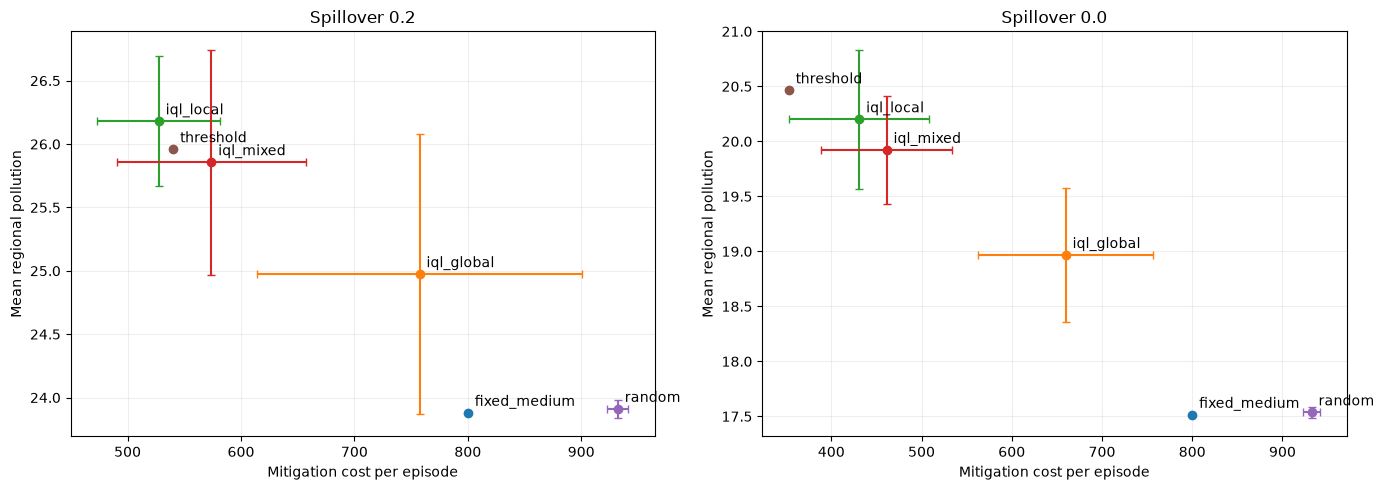

In [6]:
figure, axes = plt.subplots(1, len(scenario_directories),
                            figsize=(7 * len(scenario_directories), 5), squeeze=False)

for axis, (spillover, directory) in zip(axes[0], scenario_directories.items()):
    summary = pd.read_csv(f"{directory}/policy_summary.csv")
    for _, row in summary.iterrows():
        axis.errorbar(
            row["mitigation_cost_mean"], row["mean_regional_pollution_mean"],
            xerr=row["mitigation_cost_sd"], yerr=row["mean_regional_pollution_sd"],
            marker="o", capsize=3,
        )
        axis.annotate(row["policy"], (row["mitigation_cost_mean"],
                                      row["mean_regional_pollution_mean"]),
                      xytext=(5, 5), textcoords="offset points")
    axis.set(title=f"Spillover {spillover}", xlabel="Mitigation cost per episode",
             ylabel="Mean regional pollution")
    axis.grid(alpha=0.2)

figure.tight_layout()
plt.show()

## Results summary

At spillover 0.2, global-reward Q-learning averaged **24.97** pollution units and **757** cost units per episode. Local-reward Q-learning averaged **26.18** pollution and **527** cost. The shared reward therefore bought about **1.21 fewer pollution units** for about **230 more cost units** in the paired comparison. Mixed reward sat between them on both measures: **25.86** pollution and **574** cost.

Fixed medium (**23.88**, cost **800**) and random (**23.91**, cost **932**) had the lowest average pollution in this sample. Global-reward Q-learning used less cost than either, but it also left more pollution. No one policy wins on both pollution and cost. The threshold rule used less cost (**540**) while leaving more pollution (**25.96**).

The bars matter: at spillover 0.2, global-reward pollution varied by **1.10** and cost by **143** across training seeds (one standard deviation). Those are run-to-run spreads, not confidence intervals. At zero spillover, global and local averaged **18.97** versus **20.20** pollution, with costs of **660** versus **431**. Compare policies within each panel; removing neighbor pollution changes the level of every policy's outcomes.